In [2]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
from pathlib import Path 

print("Baseline forecasting enviornment initialized ")

Baseline forecasting enviornment initialized 


In [3]:

BASE_DIR = Path.cwd().parent
PROCESSED_DIR= BASE_DIR/"data" /"processed"

train= pd.read_csv(
    PROCESSED_DIR/ "train_daily_demand.csv"
)

validation = pd.read_csv(
    PROCESSED_DIR/"validation_daily_demand.csv"
)

train["date"]= pd.to_datetime(train["date"])
validation["date"]= pd.to_datetime(validation["date"])

print("Training shape:", train.shape)
print("Validation shape:", validation.shape)

print("nTraining Period:")
print(train["date"].min(), "to", train["date"].max())

print("Validation Period:")
print(validation["date"].min(), "to", validation["date"].max())

Training shape: (1913, 2)
Validation shape: (28, 2)
nTraining Period:
2011-01-29 00:00:00 to 2016-04-24 00:00:00
Validation Period:
2016-04-25 00:00:00 to 2016-05-22 00:00:00


In [4]:
last_train_value= train["units_sold"].iloc[-1]

naive_forecast= np.repeat(
    last_train_value,
    len(validation)
)

print("Last training demand:", last_train_value)
print("Naive forecast:")
print(naive_forecast)



Last training demand: 49795
Naive forecast:
[49795 49795 49795 49795 49795 49795 49795 49795 49795 49795 49795 49795
 49795 49795 49795 49795 49795 49795 49795 49795 49795 49795 49795 49795
 49795 49795 49795 49795]


In [8]:
from sklearn.metrics import mean_absolute_error,mean_squared_error
actual =validation["units_sold"].values

naive_mae = mean_absolute_error(
    actual,
    naive_forecast
)

naive_rmse= np.sqrt(
    mean_squared_error(
        actual,
        naive_forecast
    )
)

naive_mape= np.mean(
    np.abs(
        (actual-naive_forecast)/
        np.where(actual==0, 1, actual)
    )
)*100

print("NAIVE FORECAST RESULTS")
print("="*40)
print("MAE:", naive_mae)
print("RMSE:", naive_rmse)
print("MAPE:", naive_mape, "%")


NAIVE FORECAST RESULTS
MAE: 7890.571428571428
RMSE: 8817.170059443271
MAPE: 19.395964155973598 %


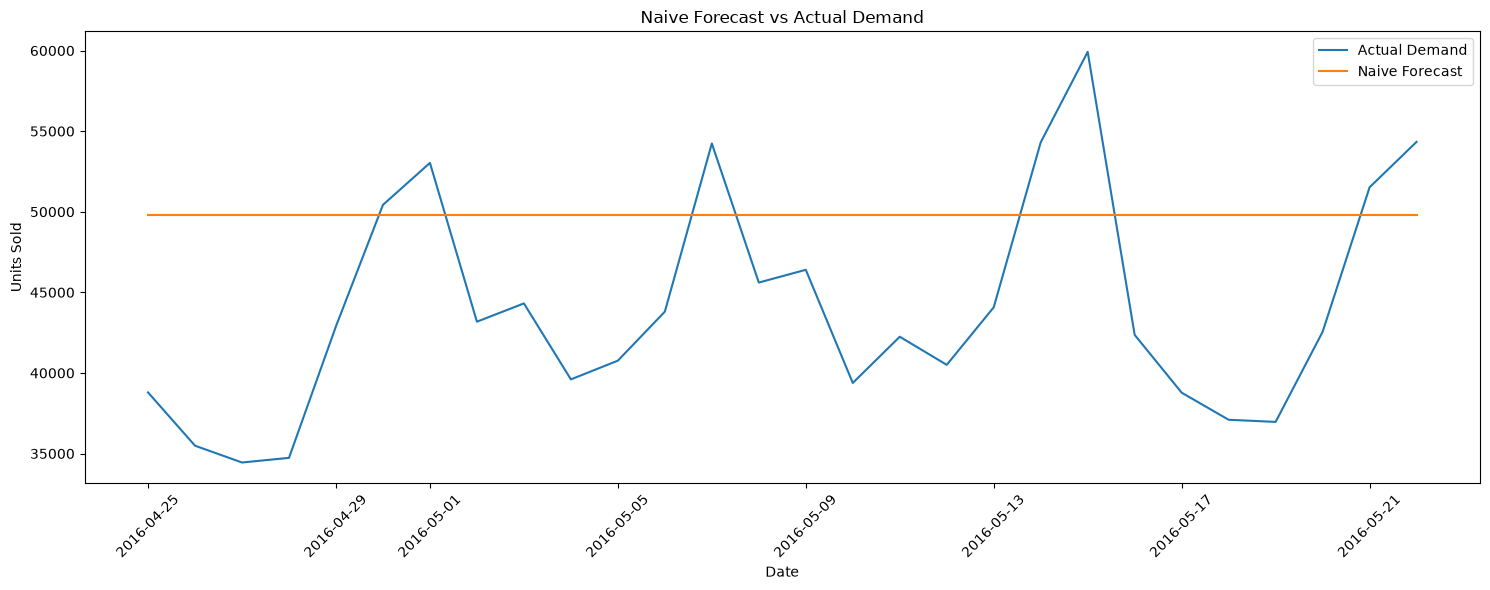

In [9]:
plt.figure(figsize=(15, 6))
plt.plot(
    validation["date"],
    actual,
    label="Actual Demand"
)

plt.plot(
    validation["date"],
    naive_forecast,
    label="Naive Forecast"
)

plt.title("Naive Forecast vs Actual Demand")
plt.xlabel("Date")
plt.ylabel("Units Sold")

plt.legend()

plt.xticks(rotation = 45)
plt.tight_layout()
plt.show()

In [10]:
last_7_days = train["units_sold"].tail(7)

moving_average_value= last_7_days.mean()

moving_average_forecast= np.repeat(
    moving_average_value,
    len(validation)
)
print("Last 7 days:")
print(last_7_days.values)
print("\n7-day average demand:", moving_average_value)


Last 7 days:
[38059 37570 35343 35033 40517 48962 49795]

7-day average demand: 40754.142857142855


In [11]:
moving_average_mae= mean_absolute_error(
    actual,
    moving_average_forecast
)

moving_average_rmse= np.sqrt(
    mean_squared_error(
        actual,
        moving_average_forecast
    )
)


moving_average_mpae= np.mean(
    np.abs(
        (actual-moving_average_forecast)/
        np.where(actual ==0 , 1, actual)
    )
)*100

print("7-DAY MOVING AVERAGE RESULTS")
print("=" * 40)
print("MAE :", moving_average_mae)
print("RMSE:", moving_average_rmse)
print("MAPE:", moving_average_mpae, "%")

7-DAY MOVING AVERAGE RESULTS
MAE : 5506.387755102041
RMSE: 7385.367183056739
MAPE: 11.620050810754464 %
